# Lab01 - Sprint 1

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

sensors = pd.read_csv('ASE10.csv', sep = ';')

sensors.head(5)

,date,ASE_NO2,ASE_NO,ASE_CO,ASE_Ox,ASE_T,ASE_HR,ASE_PA,SUD3_NO2,SUD3_NO,QDP_NO,QDP_NO2,QDP_CO,Location
0,2021-10-20 14:00,29123.75000,43733.48438,40791.60938,29087.65625,23.253516,54.889016,1006.269444,11.2,3.5,15.6,22.7,0.139,SUD3
1,2021-10-20 15:00,29084.31434,42984.14706,40922.12408,29067.22335,22.838591,56.928588,1005.413194,17.8,6.2,20.7,27.1,0.148,SUD3
2,2021-10-20 16:00,29119.26563,42667.14063,40680.23438,29099.71875,22.751450,54.193586,1004.264236,13.3,2.1,23.9,30.2,0.178,SUD3
3,2021-10-20 17:00,29110.03125,42470.15625,40709.89063,29097.42188,22.614907,54.335088,1002.840972,13.4,1.1,12.6,28.7,0.129,SUD3
4,2021-10-20 18:00,29108.90165,42257.46048,40683.00092,29086.15717,21.929122,55.553496,1001.325000,11.8,0.9,8.3,32.6,0.122,SUD3


## Random Variable 01: Сигнал сенсора NO2


### Description
Случайная величина 1 - значение напряжения на электрохимическом сенсоре NO2, измеряемое на автомобильном перекрестке. Показание сенсора нельзя рассчитать по формуле, так как на концентрацию газа в воздухе влияет количество машин на светофоре и порывы ветра. Также присутствует погрешность самого сенсора и броуновское движение молекул газа.

### EDA & Distribution


Размер данных до очистки: 3739 наблюдений.
Размер данных после очистки: 3686 наблюдений.



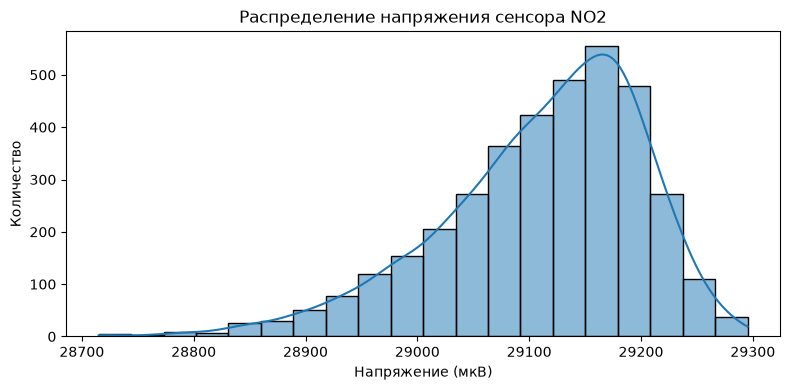

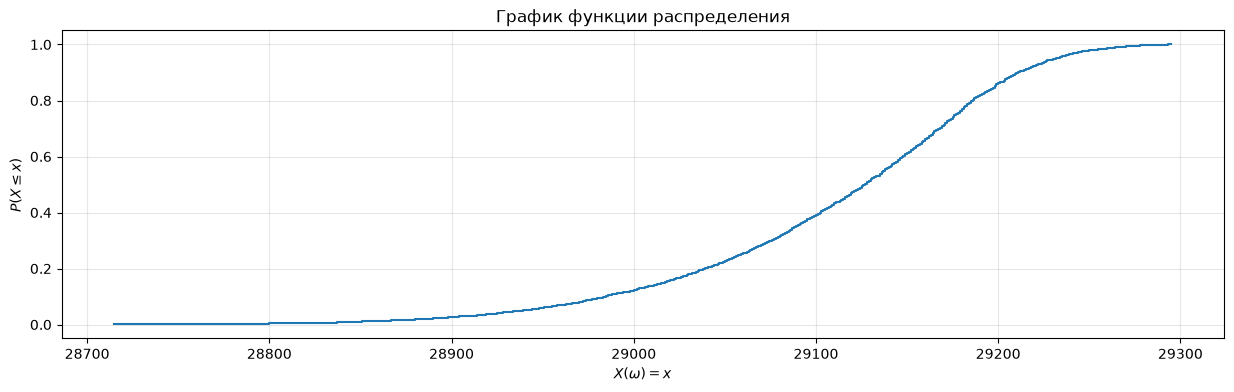


Сумма: 107306226.23449999
Среднее: 29111.835657759086
Медиана: 29128.038145
Минимум: 28715.0
Максимум: 29295.28125
Стандартное отклонение: 90.41962706444696
95-й перцентиль: 29233.165215
Дисперсия: 8175.708958473668
Мода: 29126.09375


In [9]:
no2_all = sensors['ASE_NO2']
no2 = sensors['ASE_NO2'].dropna()

print(f"\nРазмер данных до очистки: {no2_all.shape[0]} наблюдений.")
print(f"Размер данных после очистки: {no2.shape[0]} наблюдений.\n")

no2.head(5)

#распределения
fig, axes = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=no2,
    kde=True,
    ax=axes,
    bins = 20
)
axes.set_title("Распределение напряжения сенсора NO2")
axes.set_xlabel("Напряжение (мкВ)")
axes.set_ylabel("Количество")

plt.tight_layout()
plt.show()


#график ф-ции распределения
no2_round = no2.apply(lambda x: int(round(x)))
voltage = no2_round.value_counts().reset_index()
voltage['p_i'] = voltage['count'].apply(lambda x: x/no2.shape[0])

p_accum = 0

def P_func(x):
    global p_accum
    p_accum += x
    return p_accum

voltage = voltage.sort_values(by='ASE_NO2')
voltage['P'] = voltage ['p_i'].apply(lambda x: P_func(x))

fig, ax = plt.subplots(figsize=(15, 4))
ax.step(voltage['ASE_NO2'],voltage['P'])
ax.set_title("График функции распределения")
ax.set_xlabel(r"$X(\omega) = x$")
ax.set_ylabel(r"$P(X \leq x)$")
ax.grid(True, alpha=0.3)

plt.show()

#остальные метрики
print(f"\nСумма:", no2.sum())
print("Среднее:", no2.mean())
print("Медиана:", no2.median())
print("Минимум:", no2.min())
print("Максимум:", no2.max())
print("Стандартное отклонение:", no2.std())
print("95-й перцентиль:", no2.quantile(0.95))
print("Дисперсия:", no2.var())
print("Мода:", no2.mode().iloc[0])


#### Математическая база распределения
Сенсор измеряет напряжение электрода, на что влияет множество мелких случайных факторов (ветер, машины, погрешность прибора). Если случайная величина формируется под воздействием множества независимых факторов, ее распределение стремится к нормальному.
Но физически - повышение концентрации NO2 понижает показатель датчика. Эти скачки концентрации (например, из-за частых автомобильных пробок в месте измерения) привело к ассиметрии графика распределения и образованию вытянутого левого хвоста.

Математически плотность вероятности ассиметричного нормального распределение задается:
$$f(x) = \frac{2}{\omega} \phi\left(\frac{x - \xi}{\omega}\right) \Phi\left(\alpha \left(\frac{x - \xi}{\omega}\right)\right)$$

Где:
* $\phi(t)$ — стандартная нормальная плотность распределения.
* $\Phi(t)$ — функция распределения стандартного нормального закона.
* $\xi$ — параметр сдвига.
* $\omega$ — параметр масштаба.
* $\alpha$ — параметр асимметрии.

Нулевая гипотеза: распределение напряжения сенсора NO2 соответствует нормальному
Альтернативная: распределение отличается от нормального, присутствует ассиметрия

In [10]:
import scipy.stats as stats

stat, p_value = stats.normaltest(no2)

print(f"Статистика критерия: {stat}")
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("Нулевая гипотеза не верна")
else:
    print("Нулевая гипотеза верна")


Статистика критерия: 377.24614043412896
p-value: 1.2079291032735805e-82
Нулевая гипотеза не верна


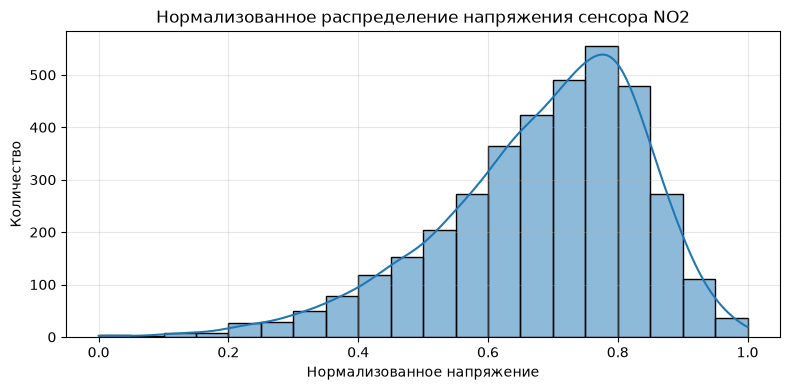

Новый минимум: 0.0
Новый максимум: 1.0
Новое среднее: 0.6838677930039768


In [11]:
min_no2 = no2.min()
max_no2 = no2.max()
no2_normalized = (no2 - min_no2) / (max_no2 - min_no2)

fig, axes = plt.subplots(figsize=(8, 4))
sns.histplot(
    data=no2_normalized,
    kde=True,
    ax=axes,
    bins=20,
)

axes.set_title("Нормализованное распределение напряжения сенсора NO2")
axes.set_xlabel("Нормализованное напряжение")
axes.set_ylabel("Количество")
axes.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Новый минимум:", no2_normalized.min())
print(f"Новый максимум:", no2_normalized.max())
print(f"Новое среднее:", no2_normalized.mean())

### Independence & Estimations
Для проверки состоятельности оценки проверим, как среднее значение ведет себя при увеличении количества случайных показаний сенсора.

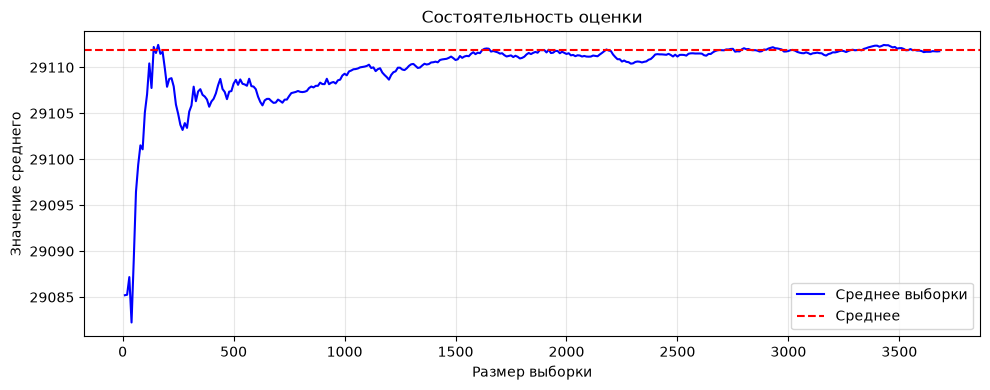

In [12]:
random_no2 = no2.sample(frac=1, random_state=40).values

sizes = np.arange(10, len(random_no2), 10)
means = [random_no2[:n].mean() for n in sizes]

plt.figure(figsize=(10, 4))
plt.plot(sizes, means, label='Среднее выборки', color='blue')
plt.axhline(no2.mean(), color='red', linestyle='--', label='Среднее')

plt.title('Состоятельность оценки')
plt.xlabel('Размер выборки')
plt.ylabel('Значение среднего')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Можно заметить, как значение среднего перестает колебаться и сводится к исходному при увеличении размера выборки.
После отметки в 600 показаний, среднее перестает сильно колебаться. Возьмем выборку размером в 600 значений и проверим ее статистику.

In [13]:
n_samples = 600

no_return = no2.sample(n=n_samples, replace=False, random_state=40)
with_return = no2.sample(n=n_samples, replace=True, random_state=40)

def get_stat(data, column_name):
    stats = {
        "Сумма": data.sum(),
        "Среднее": data.mean(),
        "Медиана": data.median(),
        "Минимум": data.min(),
        "Максимум": data.max(),
        "Стандартное отклонение": data.std(),
        "95-й перцентиль": data.quantile(0.95),
        "Дисперсия": data.var(),
        "Мода": data.mode().iloc[0],
    }
    return pd.DataFrame(stats.values(), index=stats.keys(), columns=[column_name])

df_gen = get_stat(no2, "Генеральная совокупность")
df_no_r = get_stat(no_return, "Без возвращения ")
df_with_r = get_stat(with_return, "С возвращением")

table = pd.concat([df_gen, df_no_r, df_with_r], axis=1)
display(table)

,Генеральная совокупность,Без возвращения,С возвращением
Сумма,1.073062e+08,1.746457e+07,1.746633e+07
Среднее,2.911184e+04,2.910761e+04,2.911055e+04
Медиана,2.912804e+04,2.912511e+04,2.912652e+04
Минимум,2.871500e+04,2.873198e+04,2.879690e+04
Максимум,2.929528e+04,2.929450e+04,2.927598e+04
Стандартное отклонение,9.041963e+01,9.166015e+01,8.787437e+01
95-й перцентиль,2.923317e+04,2.922880e+04,2.922898e+04
Дисперсия,8.175709e+03,8.401583e+03,7.721905e+03
Мода,2.912609e+04,2.906138e+04,2.921608e+04


Все данные, кроме суммы, очень близки к генеральной совокупности, что показывает выборку объемом 600 подходящей для суждения о ней.
Дисперсия выборки с возвращением заметно ниже, так как в нее могли попасть продублированные строки, в остальном данные не отличаются.
Выборка без возвращения в целом более похожа на оригинальную

## Random Variable 02: Сигнал сенсора CO

### Description
Случайная величина 2 - сигнал электрохимического сенсора CO (`ASE_CO`), который снимается каждый час на автомобильном перекрестке. Вычислить его по формуле нельзя: значение зависит, в частности, от того, сколько машин проехало и как дует ветер, и к этому добавляется собственный шум прибора.

### EDA & Distribution


Размер данных до очистки: 3739 наблюдений.
Размер данных после очистки: 3686 наблюдений.



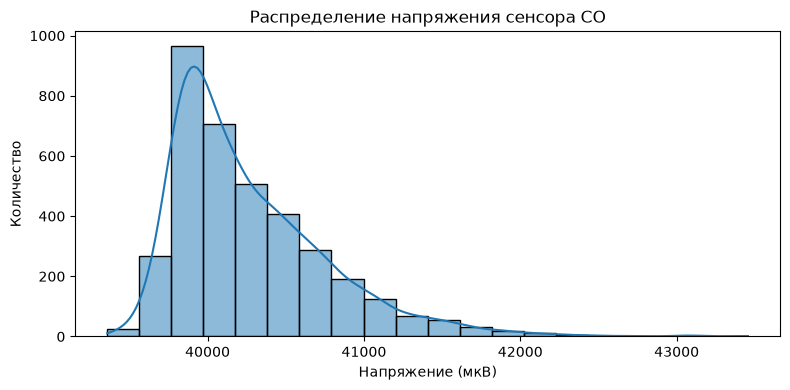

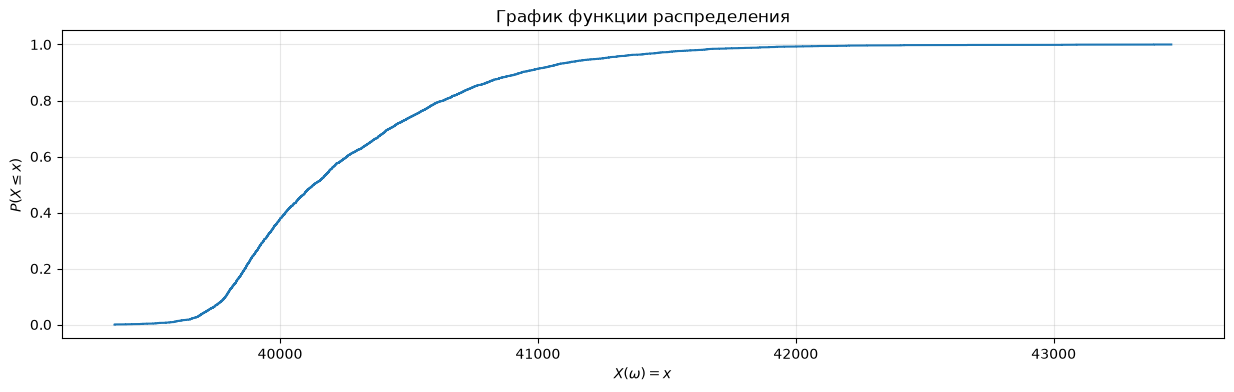


Сумма: 148429693.67587
Среднее: 40268.50072595497
Медиана: 40132.16728
Минимум: 39358.04688
Максимум: 43455.98346
Стандартное отклонение: 499.6717627929245
95-й перцентиль: 41247.7557475
Дисперсия: 249671.87053258857
Мода: 39752.20313


In [14]:
co_all = sensors['ASE_CO']
co = sensors['ASE_CO'].dropna()

print(f"\nРазмер данных до очистки: {co_all.shape[0]} наблюдений.")
print(f"Размер данных после очистки: {co.shape[0]} наблюдений.\n")

co.head(5)

#распределения
fig, axes = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=co,
    kde=True,
    ax=axes,
    bins = 20
)
axes.set_title("Распределение напряжения сенсора CO")
axes.set_xlabel("Напряжение (мкВ)")
axes.set_ylabel("Количество")

plt.tight_layout()
plt.show()


#график ф-ции распределения
co_round = co.apply(lambda x: int(round(x)))
voltage = co_round.value_counts().reset_index()
voltage['p_i'] = voltage['count'].apply(lambda x: x/co.shape[0])

p_accum = 0

def P_func(x):
    global p_accum
    p_accum += x
    return p_accum

voltage = voltage.sort_values(by='ASE_CO')
voltage['P'] = voltage ['p_i'].apply(lambda x: P_func(x))

fig, ax = plt.subplots(figsize=(15, 4))
ax.step(voltage['ASE_CO'],voltage['P'])
ax.set_title("График функции распределения")
ax.set_xlabel(r"$X(\omega) = x$")
ax.set_ylabel(r"$P(X \leq x)$")
ax.grid(True, alpha=0.3)

plt.show()

#остальные метрики
print(f"\nСумма:", co.sum())
print("Среднее:", co.mean())
print("Медиана:", co.median())
print("Минимум:", co.min())
print("Максимум:", co.max())
print("Стандартное отклонение:", co.std())
print("95-й перцентиль:", co.quantile(0.95))
print("Дисперсия:", co.var())
print("Мода:", co.mode().iloc[0])

#### Математическая база распределения

Проверим гипотезу о нормальности.
$H_0$: распределение сигнала CO нормальное.
$H_1$: распределение отличается от нормального.

In [15]:
import scipy.stats as stats

stat, p_value = stats.normaltest(co)

print(f"Статистика критерия: {stat}")
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("Нулевая гипотеза отвергается: распределение не нормальное")
else:
    print("Нет оснований отвергнуть нулевую гипотезу")

Статистика критерия: 1028.7669622714538
p-value: 4.037314305072088e-224
Нулевая гипотеза отвергается: распределение не нормальное


Skew-normal: alpha = 7.688, xi = 39687.0, omega = 766.6
Асимметрия модели skew-normal: 0.93
Асимметрия данных: 1.467
AIC skew-normal: 54990.6
AIC lognormal:   54961.4


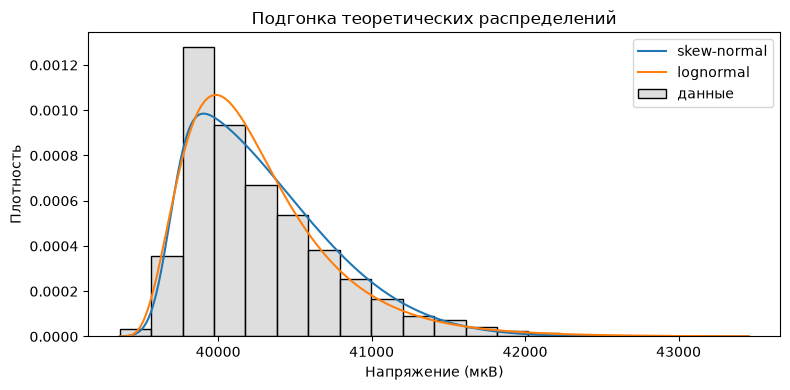

In [16]:
# подгонка теоретических распределений к данным (метод максимального правдоподобия)
a, loc_sn, scale_sn = stats.skewnorm.fit(co)
s, loc_ln, scale_ln = stats.lognorm.fit(co)

print("Skew-normal: alpha = {:.3f}, xi = {:.1f}, omega = {:.1f}".format(a, loc_sn, scale_sn))
print("Асимметрия модели skew-normal:", round(float(stats.skewnorm.stats(a, loc_sn, scale_sn, moments='s')), 3))
print("Асимметрия данных:", round(co.skew(), 3))

# сравнение моделей по AIC (чем меньше, тем лучше)
def aic(dist, params):
    return 2 * len(params) - 2 * dist.logpdf(co, *params).sum()

aic_sn = aic(stats.skewnorm, (a, loc_sn, scale_sn))
aic_ln = aic(stats.lognorm, (s, loc_ln, scale_ln))
print("AIC skew-normal:", round(aic_sn, 1))
print("AIC lognormal:  ", round(aic_ln, 1))

# теоретические плотности поверх гистограммы
x = np.linspace(co.min(), co.max(), 500)
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(co, stat='density', bins=20, ax=ax, color='lightgray', label='данные')
ax.plot(x, stats.skewnorm.pdf(x, a, loc_sn, scale_sn), label='skew-normal')
ax.plot(x, stats.lognorm.pdf(x, s, loc_ln, scale_ln), label='lognormal')
ax.set_title("Подгонка теоретических распределений")
ax.set_xlabel("Напряжение (мкВ)")
ax.set_ylabel("Плотность")
ax.legend()
plt.tight_layout()
plt.show()

In [17]:
import scipy.stats as stats

stat, p_value = stats.normaltest(co)

print(f"Статистика критерия: {stat}")
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("Нулевая гипотеза отвергается: распределение не нормальное")
else:
    print("Нет оснований отвергнуть нулевую гипотезу")

Статистика критерия: 1028.7669622714538
p-value: 4.037314305072088e-224
Нулевая гипотеза отвергается: распределение не нормальное
